In [1]:
from google.colab import files
uploaded = files.upload()

Saving images.png to images.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageOps

In [3]:
def preprocess(image_path):
    img = Image.open(image_path)
    img = img.convert("L")
    img = img.resize((300, 300))
    img = ImageOps.equalize(img)
    img = img.point(lambda x: 255 if x > 128 else 0)
    img = img.filter(ImageFilter.FIND_EDGES)

    return np.array(img)

In [5]:
from skimage.metrics import structural_similarity as compare_ssim

img1 = preprocess("images.png")
img2 = preprocess("images.png")

score, _ = compare_ssim(img1, img2, full=True)

print("SSIM =", score)

SSIM = 1.0


In [6]:
if score >= 0.75:
    print("ACCEPTEE")
else:
    print("REJETEE")

ACCEPTEE


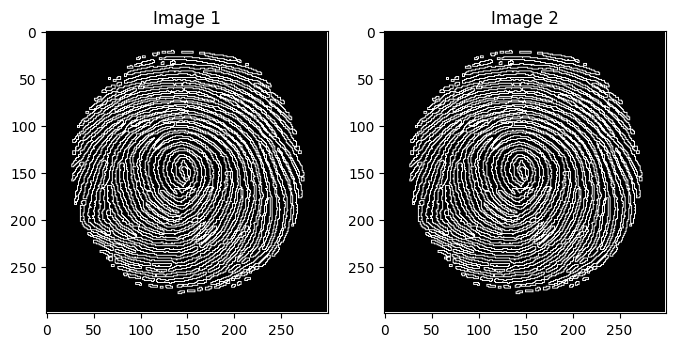

In [7]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(img1, cmap='gray')
plt.title("Image 1")

plt.subplot(1,2,2)
plt.imshow(img2, cmap='gray')
plt.title("Image 2")

plt.show()